In [2]:
# --- CELDA 1: Importaciones y Configuración ---
import random
import numpy as np
import matplotlib.pyplot as plt

# Nombre del archivo (Asegúrate que esté en la misma carpeta que el Notebook)
FILENAME = "uf20-016.cnf" 

# Parámetros del Algoritmo Genético
POP_SIZE = 50           # Cuántos individuos viven en cada generación
GENERATIONS = 1000      # Cuántas veces evolucionarán
CHROMOSOME_LEN = 20     # Longitud del cromosoma (20 variables en el problema uf20)
MUTATION_K = 4          # Cuántos bits cambiaremos al mutar (k=4 es agresivo)
RUNS = 35               # Cuántas veces repetiremos el experimento completo

print(f"Configuración lista: {POP_SIZE} individuos, {GENERATIONS} generaciones.")

Configuración lista: 50 individuos, 1000 generaciones.


In [3]:
# --- CELDA 2: Carga de Datos ---
def load_cnf(filepath):
    clauses = []
    try:
        with open(filepath, 'r') as f:
            current_clause = []
            for line in f:
                line = line.strip()
                # Ignoramos comentarios y encabezados
                if not line or line.startswith(('c', '%', '0', 'p')):
                    continue
                
                parts = [int(x) for x in line.split()]
                for num in parts:
                    if num == 0: # El 0 marca el fin de la línea
                        if current_clause:
                            clauses.append(current_clause)
                            current_clause = []
                    else:
                        current_clause.append(num)
            if current_clause:
                clauses.append(current_clause)
    except FileNotFoundError:
        print(f"❌ ERROR: No encuentro el archivo '{filepath}'.")
        return []
    return clauses

# Ejecutamos la carga
clauses = load_cnf(FILENAME)

if clauses:
    print(f"✅ Archivo cargado exitosamente.")
    print(f"Total de cláusulas (reglas) a cumplir: {len(clauses)}")
    print(f"Ejemplo de la primera regla: {clauses[0]}")
    print(f"Ejemplo de la última regla: {clauses[-1]}")

✅ Archivo cargado exitosamente.
Total de cláusulas (reglas) a cumplir: 91
Ejemplo de la primera regla: [-2, 18, -11]
Ejemplo de la última regla: [14, 20, 3]


In [4]:
# --- CELDA 3: Creación y Evaluación ---

def create_individual():
    """Crea una lista de 20 ceros y unos al azar."""
    return [random.randint(0, 1) for _ in range(CHROMOSOME_LEN)]

def evaluate(individual, clauses):
    """Cuenta cuántas reglas cumple el individuo."""
    satisfied_count = 0
    for clause in clauses:
        is_satisfied = False
        for lit in clause:
            # Truco matemático para convertir variables (1..20) a índices (0..19)
            idx = abs(lit) - 1
            val = individual[idx]
            
            # Si la regla pide positivo y tenemos 1, O la regla pide negativo y tenemos 0
            if (lit > 0 and val == 1) or (lit < 0 and val == 0):
                is_satisfied = True
                break 
        
        if is_satisfied:
            satisfied_count += 1
    return satisfied_count

# --- PRUEBA VISUAL ---
demo_ind = create_individual()
demo_fitness = evaluate(demo_ind, clauses)
print("Ejemplo de un individuo (ADN):")
print(demo_ind)
print(f"Calificación de este individuo aleatorio: {demo_fitness}/{len(clauses)}")

Ejemplo de un individuo (ADN):
[1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0]
Calificación de este individuo aleatorio: 78/91


In [5]:
# --- CELDA 4: Operadores Genéticos ---

def rank_selection(population, fitnesses):
    """Selecciona padres. Los mejores tienen más probabilidad (Ranking)."""
    sorted_indices = np.argsort(fitnesses) # Ordena del peor al mejor
    ranks = np.arange(1, len(population) + 1) # Asigna puntos: 1, 2, 3... 50
    probs = ranks / ranks.sum() # Convierte puntos en % de probabilidad
    
    # Ruleta basada en ranking
    selected_indices = np.random.choice(sorted_indices, size=len(population), p=probs, replace=True)
    return [population[i] for i in selected_indices]

def crossover_two_point(p1, p2):
    """Cruza dos padres cortándolos en dos puntos."""
    # Elegimos 2 puntos de corte al azar
    pts = sorted(random.sample(range(1, CHROMOSOME_LEN), 2))
    pt1, pt2 = pts[0], pts[1]
    
    # Creamos hijos mezclando partes
    c1 = p1[:pt1] + p2[pt1:pt2] + p1[pt2:]
    c2 = p2[:pt1] + p1[pt1:pt2] + p2[pt2:]
    return c1, c2

def mutate_k_bits(individual, k):
    """Cambia k bits al azar (inversión)."""
    indices = random.sample(range(CHROMOSOME_LEN), k)
    new_ind = individual[:]
    for idx in indices:
        new_ind[idx] = 1 - new_ind[idx] # Cambia 0 a 1, o 1 a 0
    return new_ind

print("Operadores definidos.")

Operadores definidos.


In [6]:
# --- CELDA 5: Función Principal del GA ---

def genetic_algorithm_run():
    # 1. Población inicial
    population = [create_individual() for _ in range(POP_SIZE)]
    history_best_fitness = []
    best_fitness_ever = 0
    
    # Guardamos el mejor individuo de la historia (Elitismo)
    best_ind_ever = None

    for gen in range(GENERATIONS):
        # 2. Evaluar
        fitnesses = [evaluate(ind, clauses) for ind in population]
        
        # Estadísticas
        current_best_val = max(fitnesses)
        best_idx = np.argmax(fitnesses)
        
        history_best_fitness.append(current_best_val)
        
        if current_best_val > best_fitness_ever:
            best_fitness_ever = current_best_val
            best_ind_ever = population[best_idx][:] # Copia del mejor
        
        # 3. Selección
        mating_pool = rank_selection(population, fitnesses)
        
        # 4. Nueva Generación
        new_population = []
        
        # ELITISMO: ¡El mejor pasa directo sin cambios!
        if best_ind_ever:
            new_population.append(best_ind_ever[:])
        else:
            new_population.append(population[best_idx][:])
            
        # Rellenar el resto con hijos
        while len(new_population) < POP_SIZE:
            p1 = random.choice(mating_pool)
            p2 = random.choice(mating_pool)
            
            c1, c2 = crossover_two_point(p1, p2)
            
            # Mutación obligatoria según tus requisitos
            c1 = mutate_k_bits(c1, MUTATION_K)
            c2 = mutate_k_bits(c2, MUTATION_K)
            
            new_population.append(c1)
            if len(new_population) < POP_SIZE:
                new_population.append(c2)
        
        population = new_population

    return history_best_fitness, best_fitness_ever

print("Motor del algoritmo listo.")

Motor del algoritmo listo.


In [7]:
# --- CELDA 6: Ejecución Experimental ---
print(f"Iniciando {RUNS} ejecuciones independientes...")

all_runs_history = []
final_best_fitnesses = []

for r in range(RUNS):
    print(f"\n========== INICIANDO CORRIDA {r+1}/{RUNS} ==========")
    
    # Ejecutamos el algoritmo
    hist, best_fit = genetic_algorithm_run()
    
    # Imprimir el fitness de cada una de las épocas
    for epoca in range(len(hist)):
        print(f"Corrida {r+1} | Época {epoca + 1}: Mejor Fitness = {hist[epoca]}")
    
    # Guardamos los resultados
    all_runs_history.append(hist)
    final_best_fitnesses.append(best_fit)
    
    print(f"-> FIN DE LA CORRIDA {r+1}. Mejor global logrado: {best_fit}")

print("\n¡Experimento finalizado!")

Iniciando 35 ejecuciones independientes...

========== INICIANDO CORRIDA 1/35 ==========
Corrida 1 | Época 1: Mejor Fitness = 88
Corrida 1 | Época 2: Mejor Fitness = 88
Corrida 1 | Época 3: Mejor Fitness = 88
Corrida 1 | Época 4: Mejor Fitness = 88
Corrida 1 | Época 5: Mejor Fitness = 88
Corrida 1 | Época 6: Mejor Fitness = 88
Corrida 1 | Época 7: Mejor Fitness = 88
Corrida 1 | Época 8: Mejor Fitness = 88
Corrida 1 | Época 9: Mejor Fitness = 88
Corrida 1 | Época 10: Mejor Fitness = 88
Corrida 1 | Época 11: Mejor Fitness = 88
Corrida 1 | Época 12: Mejor Fitness = 88
Corrida 1 | Época 13: Mejor Fitness = 88
Corrida 1 | Época 14: Mejor Fitness = 88
Corrida 1 | Época 15: Mejor Fitness = 88
Corrida 1 | Época 16: Mejor Fitness = 88
Corrida 1 | Época 17: Mejor Fitness = 88
Corrida 1 | Época 18: Mejor Fitness = 88
Corrida 1 | Época 19: Mejor Fitness = 88
Corrida 1 | Época 20: Mejor Fitness = 88
Corrida 1 | Época 21: Mejor Fitness = 88
Corrida 1 | Época 22: Mejor Fitness = 88
Corrida 1 | Época 

In [8]:
# --- CELDA 6.1: Resumen del Mejor Fitness por Corrida ---

print("==================================================")
print("   RESUMEN DE MEJOR FITNESS POR EJECUCIÓN")
print("==================================================")

# Imprimir el resultado individual de cada corrida
for i, fitness in enumerate(final_best_fitnesses):
    # El :02d es solo para que los números del 1 al 9 tengan un cero a la izquierda (ej. 01, 02) 
    # y la tabla se vea alineada.
    print(f"Corrida {i + 1:02d} | Mejor Fitness Alcanzado: {fitness}")

print("\n==================================================")
print("               ESTADÍSTICAS FINALES               ")
print("==================================================")
# Calcular estadísticas rápidas
mejor_global = max(final_best_fitnesses)
peor_global = min(final_best_fitnesses)
promedio = sum(final_best_fitnesses) / len(final_best_fitnesses)

print(f"Mejor resultado de las 35 corridas: {mejor_global}")
print(f"Peor resultado de las 35 corridas:  {peor_global}")
print(f"Promedio general de efectividad:    {promedio:.2f}")
print("==================================================")

   RESUMEN DE MEJOR FITNESS POR EJECUCIÓN
Corrida 01 | Mejor Fitness Alcanzado: 91
Corrida 02 | Mejor Fitness Alcanzado: 91
Corrida 03 | Mejor Fitness Alcanzado: 91
Corrida 04 | Mejor Fitness Alcanzado: 91
Corrida 05 | Mejor Fitness Alcanzado: 91
Corrida 06 | Mejor Fitness Alcanzado: 91
Corrida 07 | Mejor Fitness Alcanzado: 91
Corrida 08 | Mejor Fitness Alcanzado: 90
Corrida 09 | Mejor Fitness Alcanzado: 91
Corrida 10 | Mejor Fitness Alcanzado: 91
Corrida 11 | Mejor Fitness Alcanzado: 91
Corrida 12 | Mejor Fitness Alcanzado: 91
Corrida 13 | Mejor Fitness Alcanzado: 90
Corrida 14 | Mejor Fitness Alcanzado: 91
Corrida 15 | Mejor Fitness Alcanzado: 91
Corrida 16 | Mejor Fitness Alcanzado: 91
Corrida 17 | Mejor Fitness Alcanzado: 90
Corrida 18 | Mejor Fitness Alcanzado: 90
Corrida 19 | Mejor Fitness Alcanzado: 90
Corrida 20 | Mejor Fitness Alcanzado: 91
Corrida 21 | Mejor Fitness Alcanzado: 91
Corrida 22 | Mejor Fitness Alcanzado: 91
Corrida 23 | Mejor Fitness Alcanzado: 90
Corrida 24 | Me

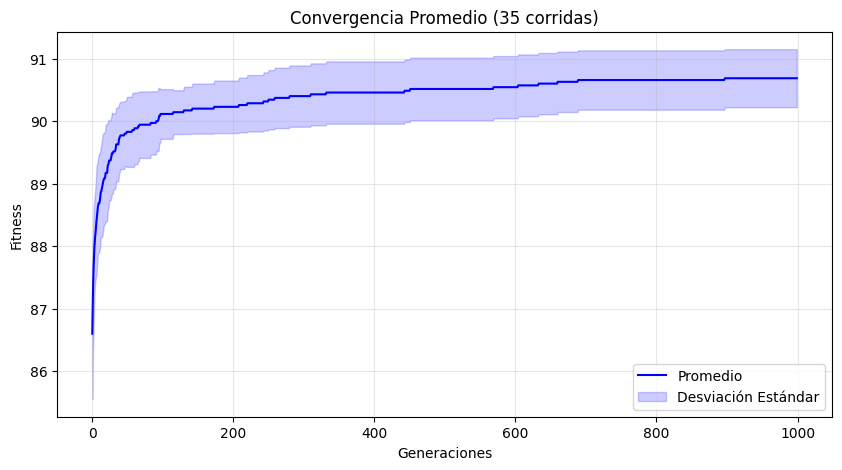

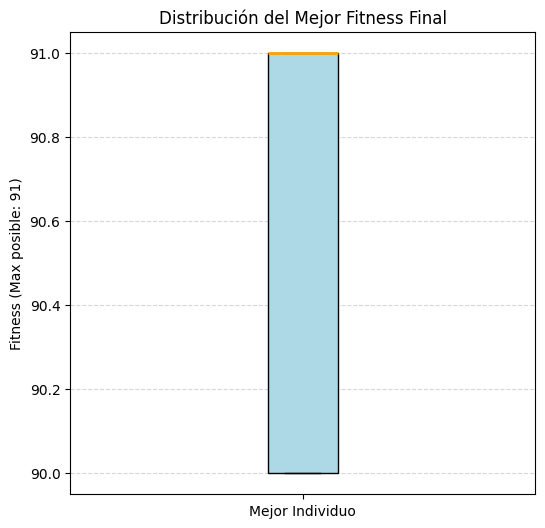

Promedio final: 90.68571428571428


In [9]:
# --- CELDA 7: Gráficas ---

# Preparar datos
data_matrix = np.array(all_runs_history)
mean_fitness = np.mean(data_matrix, axis=0)
std_fitness = np.std(data_matrix, axis=0)
epochs = np.arange(GENERATIONS)

# 1. Gráfica de Convergencia
plt.figure(figsize=(10, 5))
plt.plot(epochs, mean_fitness, label='Promedio', color='blue')
plt.fill_between(epochs, mean_fitness - std_fitness, mean_fitness + std_fitness, 
                 color='blue', alpha=0.2, label='Desviación Estándar')
plt.title('Convergencia Promedio (35 corridas)')
plt.xlabel('Generaciones')
plt.ylabel('Fitness')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 2. Boxplot
plt.figure(figsize=(6, 6))
bp = plt.boxplot(final_best_fitnesses, vert=True, patch_artist=True)

# Colorear
for patch in bp['boxes']:
    patch.set_facecolor('lightblue')
    patch.set_linewidth(1)
for median in bp['medians']:
    median.set_color('orange')
    median.set_linewidth(2)

plt.title('Distribución del Mejor Fitness Final')
plt.ylabel('Fitness (Max posible: 91)')
plt.xticks([1], ['Mejor Individuo'])
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

print(f"Promedio final: {np.mean(final_best_fitnesses)}")